# Soil pH Analysis in Nigeria Using Python

**Project:** GIFTIII Research Project — Agricultural Engineering

**Authors:** Vivian Moyosore Gomes and Emmanuel Oladeji Mustapha

**Notebook purpose:** To analyse the distribution and variability of soil pH across Nigeria using Python.

---

## Notebook Overview

This notebook carries out a descriptive analysis of soil pH in Nigeria using the AfSIS Nigeria soil dataset (accessed via iSDA). The analysis is organised into seven steps that follow the project's proposed methodology:

| Step | Description |
|---|---|
| **Step 1** | Data Importation — load the dataset and examine its structure |
| **Step 2** | Geographic Filtering — retain records within Nigeria's boundaries |
| **Step 3** | Data Cleaning and Preparation — check missing values, types and duplicates |
| **Step 4** | Descriptive Statistical Analysis — summarise pH using Pandas and NumPy |
| **Step 5** | Spatial Visualisation — scatter plot of longitude vs latitude, coloured by pH |
| **Step 6** | Distribution and Outlier Analysis — histogram, box plot and depth comparison |
| **Step 7** | Interpretation and Reporting — discuss patterns, relevance and limitations |

**Tools used:** Python 3, Pandas, NumPy, Matplotlib.

**Environment:** Jupyter Notebook.

**Outputs:** Figures saved to `figures/`, summary tables saved as CSV, written interpretation in Step 7.

## About the Dataset

The analysis uses the **AfSIS Nigeria soil dataset (accessed via iSDA)**. It contains soil observations collected at sampling sites across Nigeria, together with geographic coordinates, depth information, and a range of soil properties.

### Dataset at a glance

- **Geographic coverage:** Nigeria. The bounding box used for filtering is approximately longitude 2.7°–14.7°E and latitude 4.3°–13.9°N, but the sampling sites actually fall within about 4.4°–11.7°E and 5.2°–11.6°N (see Steps 1 and 2)
- **Observation types:** Two source types are present - **afsis_spectral** and **afsis_wetchem**
- **Depth categories:** Topsoil (0–20 cm) and subsoil (20–50 cm)
- **Variable of interest:** Soil pH (ph)

### Important note on data handling

The raw data file is stored in data_raw/ and is **never edited**. All cleaning and filtering in this notebook operates on the data in memory. Any modified data is written to a separate folder (figures/ for outputs, data_clean/ if needed), never over the raw file.

## Column Dictionary

The dataset contains the following columns. Columns marked *(key)* are those used directly in this analysis.

| Column | Meaning | Role in this analysis |
|---|---|---|
| `longitude` *(key)* | East–west geographic coordinate of the sample (°E) | Used for geographic filtering and the spatial scatter plot |
| `latitude` *(key)* | North–south geographic coordinate of the sample (°N) | Used for geographic filtering and the spatial scatter plot |
| `ph` *(key)* | Soil pH — measure of soil acidity/alkalinity | **The variable of interest.** Analysed in Steps 4–6 |
| `source` *(key)* | Data source type: `afsis_spectral` or `afsis_wetchem` | Noted in Step 3 to document method differences |
| `horizon_upper` *(key)* | Upper depth of the soil horizon sampled (cm) | Used in Step 6 to compare topsoil and subsoil |
| `horizon_lower` *(key)* | Lower depth of the soil horizon sampled (cm) | Used in Step 6 to compare topsoil and subsoil |
| `start_date` | Start date of the sampling period | Documentation only; not used |
| `end_date` | End date of the sampling period | Documentation only; not used |
| `aluminium_extractable` | Extractable aluminium concentration | Not analysed (outside pH scope) |
| `boron_extractable` | Extractable boron concentration | Not analysed (sparse in the data) |
| `calcium_extractable` | Extractable calcium concentration | Not analysed |
| `carbon_organic` | Organic carbon content | Not analysed |
| `carbon_total` | Total carbon content | Not analysed (about half empty) |
| `copper_extractable` | Extractable copper concentration | Not analysed |
| `electrical_conductivity` | Electrical conductivity (salinity indicator) | Not analysed (sparse in the data) |
| `iron_extractable` | Extractable iron concentration | Not analysed |
| `magnesium_extractable` | Extractable magnesium concentration | Not analysed |
| `manganese_extractable` | Extractable manganese concentration | Not analysed |
| `nitrogen_total` | Total nitrogen content | Not analysed |
| `phosphorus_extractable` | Extractable phosphorus concentration | Not analysed (sparse in the data) |
| `potassium_extractable` | Extractable potassium concentration | Not analysed |
| `sodium_extractable` | Extractable sodium concentration | Not analysed (sparse in the data) |
| `sulphur_extractable` | Extractable sulphur concentration | Not analysed (sparse in the data) |
| `zinc_extractable` | Extractable zinc concentration | Not analysed (sparse in the data) |

### Why only pH is analysed

The project is deliberately scoped to **soil pH only**, for three reasons:

1. **pH is the most widely used single indicator of soil condition.** It governs nutrient availability, microbial activity and crop suitability.
2. **The project's aim is a preliminary assessment**, not a full soil characterisation. Analysing every property would go beyond the scope.
3. **Other properties are recorded for future work.** The dataset supports a broader analysis, but this project describes pH patterns only — as stated in the proposal and methodology.

### Note on missing columns

Several columns (boron, electrical conductivity, phosphorus, sodium, sulphur, zinc) have only 2109 non-missing values, matching the number of `afsis_wetchem` records, so they appear to be empty for the `afsis_spectral` records. `carbon_total` has only 2048 non-missing values, matching the number of `afsis_spectral` records, so it appears to be the reverse. Because they are about half empty, these columns are **not suitable for this analysis** and are not used. `ph` and `potassium_extractable` are complete (4157 values), but only `ph` is in scope. The source-type counts are documented in Step 3.

## How to Read This Notebook

- **Markdown cells** (like this one) explain what is being done and why.
- **Code cells** contain the Python that performs the analysis. They can be run with `Shift + Enter`.
- **Output cells** appear below each code cell after running.

Each step begins with a markdown header (`# Step N: ...`), followed by a short explanation, then the code, and finally a markdown cell titled **"Step N observations"** that records what the output showed.

### Reproducibility

To reproduce this analysis:

1. Place the raw dataset in `data_raw/` (see `data_raw/README.md`).
2. Ensure `figures/` exists.
3. Run all cells top to bottom: **Kernel → Restart & Run All**.

Running the notebook top to bottom is the only way to guarantee the results are consistent. Running cells out of order can leave stale output that misrepresents the data.

## Expected Outputs

At the end of this notebook the following outputs will exist:

### Figures (saved to `figures/`)

| File | Content |
|---|---|
| `step5_spatial_basic.png` | Scatter plot of sampling locations |
| `step5_spatial_ph_coloured.png` | Scatter plot coloured by pH value |
| `step6_ph_histogram.png` | Frequency distribution of soil pH |
| `step6_ph_boxplot.png` | Box plot showing median, quartiles and outliers |
| `step6_ph_by_depth.png` | Box plots comparing topsoil and subsoil pH |

### Summary tables (saved to `figures/`)

| File | Content |
|---|---|
| `soil_ph_summary.csv` | Descriptive statistics table from Step 4 |
| `step7_final_summary.csv` | Consolidated summary of all key metrics |

### Written outputs (in Step 7)

- Interpretation of pH patterns and spatial variation
- Relevance to agricultural soil assessment
- Stated limitations of the analysis
- Conclusion addressing the project aim

---

In [1]:
# pandas for data handling, NumPy for numerical operations, matplotlib for plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

*STEP 1: Data Importation and Inspection*
=

### *In this step, the AfSIS Nigeria soil dataset is imported into Python using Pandas. The structure of the dataset is examined, its rows, columns, data types, and the soil pH variable, before any filtering or cleaning is carried out.*

In [2]:
# NOTE: reads the CSV from the same folder as this notebook.
# If you move it into data_raw/ (as described above), change the path to "data_raw/Nigeria_soil_data_preliminary.csv".
# Load the AfSIS Nigeria soil dataset from CSV into a DataFrame
df = pd.read_csv("Nigeria_soil_data_preliminary.csv")

In [3]:
# head(10) shows the first 10 rows; Jupyter hides the middle columns with '...' because the table is wide
# Preview the first 10 rows to see the columns and typical values
df.head(10)

,longitude,latitude,start_date,end_date,source,horizon_lower,horizon_upper,aluminium_extractable,boron_extractable,calcium_extractable,...,iron_extractable,magnesium_extractable,manganese_extractable,nitrogen_total,ph,phosphorus_extractable,potassium_extractable,sodium_extractable,sulphur_extractable,zinc_extractable
0,10.23145,5.22749,1/1/2008,31/12/2018,afsis_spectral,50,20,1560.440,NaN,788.519,...,80.751,164.819,55.148,2.54,5.264,NaN,166.184,NaN,NaN,NaN
1,10.29363,5.22770,1/1/2008,31/12/2018,afsis_spectral,50,20,1330.957,NaN,868.596,...,108.958,217.552,120.974,1.67,5.981,NaN,184.767,NaN,NaN,NaN
2,10.29536,5.22800,1/1/2008,31/12/2018,afsis_spectral,50,20,1462.147,NaN,666.974,...,106.923,194.957,89.063,1.11,5.227,NaN,132.120,NaN,NaN,NaN
3,10.28907,5.22820,1/1/2008,31/12/2018,afsis_spectral,50,20,1233.879,NaN,656.367,...,112.911,190.296,84.676,2.11,5.307,NaN,115.311,NaN,NaN,NaN
4,10.29127,5.22860,1/1/2008,31/12/2018,afsis_spectral,50,20,1507.737,NaN,940.170,...,97.847,200.624,109.150,2.14,5.525,NaN,121.878,NaN,NaN,NaN
5,10.28936,5.22866,1/1/2008,31/12/2018,afsis_spectral,50,20,1369.867,NaN,197.613,...,141.062,97.109,4.184,2.20,4.976,NaN,76.090,NaN,NaN,NaN
6,10.28929,5.22883,1/1/2008,31/12/2018,afsis_spectral,50,20,1267.450,NaN,444.743,...,116.022,112.873,86.612,1.57,5.238,NaN,97.601,NaN,NaN,NaN
7,10.22791,5.22986,1/1/2008,31/12/2018,afsis_spectral,50,20,1210.458,NaN,378.306,...,86.871,148.739,80.807,1.41,5.535,NaN,133.015,NaN,NaN,NaN
8,10.29380,5.23128,1/1/2008,31/12/2018,afsis_spectral,50,20,1302.862,NaN,874.610,...,150.709,168.978,89.453,2.33,5.520,NaN,180.068,NaN,NaN,NaN
9,10.22731,5.23193,1/1/2008,31/12/2018,afsis_spectral,50,20,1170.198,NaN,1046.799,...,79.574,197.210,73.992,2.44,5.853,NaN,182.714,NaN,NaN,NaN


In [4]:
# (number of rows, number of columns)
df.shape

(4157, 24)

In [5]:
# df.shape returns a tuple (rows, columns); index 0 gives the row count, index 1 the column count
# .shape is a tuple: index 0 = rows, index 1 = columns
data_sharp = df.shape
print(f"Number of rows: {data_sharp[0]}")
print(f"Number of columns: {data_sharp[1]}")

Number of rows: 4157
Number of columns: 24


In [6]:
# Column names, non-null counts and data types (helps spot missing data and wrongly typed columns)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4157 entries, 0 to 4156
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   longitude                4157 non-null   float64
 1   latitude                 4157 non-null   float64
 2   start_date               4157 non-null   object 
 3   end_date                 4157 non-null   object 
 4   source                   4157 non-null   object 
 5   horizon_lower            4157 non-null   int64  
 6   horizon_upper            4157 non-null   int64  
 7   aluminium_extractable    4157 non-null   float64
 8   boron_extractable        2109 non-null   float64
 9   calcium_extractable      4157 non-null   float64
 10  carbon_organic           4157 non-null   float64
 11  carbon_total             2048 non-null   float64
 12  copper_extractable       4157 non-null   float64
 13  electrical_conductivity  2109 non-null   float64
 14  iron_extractable        

In [7]:
# List all 24 column names (should match the Column Dictionary above)
# List all column names
df.columns

Index(['longitude', 'latitude', 'start_date', 'end_date', 'source',
       'horizon_lower', 'horizon_upper', 'aluminium_extractable',
       'boron_extractable', 'calcium_extractable', 'carbon_organic',
       'carbon_total', 'copper_extractable', 'electrical_conductivity',
       'iron_extractable', 'magnesium_extractable', 'manganese_extractable',
       'nitrogen_total', 'ph', 'phosphorus_extractable',
       'potassium_extractable', 'sodium_extractable', 'sulphur_extractable',
       'zinc_extractable'],
      dtype='object')

In [8]:
# Inspect the soil pH column, the main variable of this study:
# its data type, a sample of values, and summary statistics (count, mean, min, max, quartiles)
data_type = df["ph"].dtype
print(f"pH column data type: {data_type}")
print()
print(f"First 10 pH values:")
print(df["ph"].head(10))
print()
print(f"Summary of pH values:")
print(df["ph"].describe())

pH column data type: float64

First 10 pH values:
0    5.264
1    5.981
2    5.227
3    5.307
4    5.525
5    4.976
6    5.238
7    5.535
8    5.520
9    5.853
Name: ph, dtype: float64

Summary of pH values:
count    4157.000000
mean        5.917814
std         0.480408
min         3.990000
25%         5.644000
50%         5.963000
75%         6.237000
max         7.945400
Name: ph, dtype: float64


In [9]:
# NOTE: f-strings that reuse the same quote type inside {...} need Python 3.12+ (this notebook runs on 3.13).
# On older Python, use single quotes inside the braces, e.g. df['longitude'].
# Check the coordinate ranges to confirm the samples fall within Nigeria
# (longitude = east-west position, latitude = north-south position)
print(f"Longitude range: {df["longitude"].min()} to {df["longitude"].max()}")
print(f"Latitude range: {df["latitude"].min()} to {df["latitude"].max()}")

Longitude range: 4.4303 to 11.71565
Latitude range: 5.22749 to 11.61652


In [10]:
# Source types: afsis_wetchem = laboratory (wet chemistry) measurements; afsis_spectral = spectroscopy-based records
# Depth pairs: (0, 20) = topsoil and (20, 50) = subsoil
# Count the records from each data source; dropna = False also counts missing entries
print(f"Source Types")
print(f"{df["source"].value_counts(dropna = False)}")
print()
# Count records for each depth range (horizon_upper to horizon_lower, in cm)
print(f"{df[["horizon_upper", "horizon_lower"]].value_counts(dropna = False)}")

Source Types
source
afsis_wetchem     2109
afsis_spectral    2048
Name: count, dtype: int64

horizon_upper  horizon_lower
0              20               3146
20             50               1011
Name: count, dtype: int64


## Step 1 observations

- The dataset was loaded successfully with **4157 rows** and **24 columns**.
- The ph column is numeric and populated, and will be the focus of the analysis.
- Longitude and latitude fall within Nigeria's geographic range, confirming that the dataset covers the intended study area.
- The dataset contains two source types (afsis_spectral and afsis_wetchem) and two depth categories (topsoil 0–20 cm and subsoil 20–50 cm), which will be noted in the cleaning step.
- The summary of the `ph` column shows values from **3.990 to 7.945** with a mean of **5.918** and a median of **5.963**, so the average soil is below neutral (pH 7).
- Several nutrient columns (boron, electrical conductivity, phosphorus, sodium, sulphur, zinc) have only **2109** non-missing values and `carbon_total` only **2048**, so they are about half empty. This supports focusing on pH, which is complete.
- The sampled coordinates run from about **4.43°E to 11.72°E** and **5.23°N to 11.62°N**, which is narrower than the whole country (see Step 2).

*STEP 2: Geographical Filtering*
=

### *In this step, the dataset is filtered to retain only records located within Nigeria's geographic boundaries. Nigeria lies approximately between longitude 2.7°E and 14.7°E, and latitude 4.3°N and 13.9°N. Records outside these bounds are excluded so that subsequent analysis describes soil pH within the intended study area.*

In [11]:
# Save the record count before filtering so we can report how many rows are removed
rows_before = len(df)
print(f"Records before filtering: {rows_before}")

Records before filtering: 4157


In [12]:
# Keep only records inside Nigeria's bounding box:
# longitude 2.7 to 14.7 AND latitude 4.3 to 13.9 (& means all four conditions must be true).
# .copy() makes an independent DataFrame so later changes don't affect the original df
df_nigeria = df[
    (df["longitude"] >= 2.7) & (df["longitude"]<= 14.7) & 
    (df["latitude"] >= 4.3) & (df["latitude"] <= 13.9)
    ].copy()

print(f"Records after filtering: {len(df_nigeria)}")

Records after filtering: 4157


In [13]:
# Showing the filtered DataFrame (the last expression in a cell is displayed automatically; the middle is truncated with '...')
# Display the filtered DataFrame
df_nigeria

,longitude,latitude,start_date,end_date,source,horizon_lower,horizon_upper,aluminium_extractable,boron_extractable,calcium_extractable,...,iron_extractable,magnesium_extractable,manganese_extractable,nitrogen_total,ph,phosphorus_extractable,potassium_extractable,sodium_extractable,sulphur_extractable,zinc_extractable
0,10.23145,5.22749,1/1/2008,31/12/2018,afsis_spectral,50,20,1560.440,NaN,788.519,...,80.7510,164.8190,55.1480,2.540000,5.26400,NaN,166.1840,NaN,NaN,NaN
1,10.29363,5.22770,1/1/2008,31/12/2018,afsis_spectral,50,20,1330.957,NaN,868.596,...,108.9580,217.5520,120.9740,1.670000,5.98100,NaN,184.7670,NaN,NaN,NaN
2,10.29536,5.22800,1/1/2008,31/12/2018,afsis_spectral,50,20,1462.147,NaN,666.974,...,106.9230,194.9570,89.0630,1.110000,5.22700,NaN,132.1200,NaN,NaN,NaN
3,10.28907,5.22820,1/1/2008,31/12/2018,afsis_spectral,50,20,1233.879,NaN,656.367,...,112.9110,190.2960,84.6760,2.110000,5.30700,NaN,115.3110,NaN,NaN,NaN
4,10.29127,5.22860,1/1/2008,31/12/2018,afsis_spectral,50,20,1507.737,NaN,940.170,...,97.8470,200.6240,109.1500,2.140000,5.52500,NaN,121.8780,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4152,5.40560,9.96670,1/1/2008,31/12/2018,afsis_wetchem,20,0,603.853,0.009808,556.403,...,127.6390,160.9160,48.7272,0.311996,6.10499,3.39155,63.5178,32.4597,6.63695,0.911567
4153,6.06999,9.47827,1/1/2008,31/12/2018,afsis_wetchem,20,0,389.657,0.009814,500.418,...,77.0705,82.4535,36.2921,0.285395,6.31601,4.03134,55.9082,14.8438,5.75685,0.882494
4154,8.65110,8.36451,1/1/2008,31/12/2018,afsis_wetchem,20,0,1056.900,0.009823,692.423,...,136.3560,141.6030,57.8749,0.624507,5.86257,2.53468,91.2150,35.2692,8.79315,1.039760
4155,11.39654,9.14604,1/1/2008,31/12/2018,afsis_wetchem,20,0,320.713,0.009902,475.510,...,93.7379,49.6931,22.9532,0.337149,5.97490,9.60043,48.5838,37.9947,5.34999,0.858591


In [14]:
# Number of records the filter removed
removed = rows_before - len(df_nigeria)
print(f"Records removed: {removed}")
print()
# The retained ranges should sit inside the bounding box limits
print(f"Retained longitude range: {df_nigeria["longitude"].min()} to {df_nigeria["longitude"].max()}")
print(f"Retained latitude range: {df_nigeria["latitude"].min()} to {df_nigeria["latitude"].max()}")

# Sanity check: records outside the box (| means OR). The filter is applied to the
# ORIGINAL df, so this counts the rows that were excluded; it should equal "Records removed"
outside = df[
    (df["longitude"] < 2.7) | (df["longitude"] > 14.7) |
    (df["latitude"] < 4.3) | (df["latitude"] > 13.9)
    ]
print()
print(f"Records outside the box after filtering: {len(outside)}")

Records removed: 0

Retained longitude range: 4.4303 to 11.71565
Retained latitude range: 5.22749 to 11.61652

Records outside the box after filtering: 0


In [15]:
# Report how many pH values are present or missing in the filtered data
# (.notnull().sum() counts non-missing entries, .isnull().sum() counts missing ones)
print(f"pH values in filtered dataset:")
print(f"""
Total records   : {len(df_nigeria)}
Non-missing pH  : {df_nigeria["ph"].notnull().sum()}
Missing pH      : {df_nigeria["ph"].isnull().sum()}
""")

pH values in filtered dataset:

Total records   : 4157
Non-missing pH  : 4157
Missing pH      : 0



## Step 2 observations

- Nigeria's geographic boundaries were applied as longitude 2.7°–14.7°E and latitude 4.3°–13.9°N.
- **4157 records** were retained out of **4157 records** in the full dataset, leaving **0 records removed** as outside the study area.
- All retained records fall within the bounding box, confirmed by the sanity check returning zero out-of-bounds records.
- The filtered dataset retains **4157** records with non-missing pH values, which will carry forward into the cleaning and analysis steps.
- The bounding box is wider than the area actually sampled (observed: 4.43°–11.72°E and 5.23°–11.62°N). The filter therefore removed nothing, but the dataset has **no samples in the far north, far north-east or along the southern edge of the box**. This is a coverage limitation to bear in mind when interpreting the results.

*STEP 3: Data Cleaning and Preparation*
=

### *In this step, the filtered dataset is checked for missing values, non-numeric entries and duplicate records. The pH column is confirmed to be numeric, the number of missing pH values is documented, and the two source types in the dataset are noted. The pH and coordinate columns are then prepared for analysis, without automatically removing unusual but potentially valid measurements.*

In [16]:
# Columns that matter for this analysis (location, pH, source and depth)
key_cols = [ "longitude", "latitude", "ph", "source", "horizon_upper", "horizon_lower"]

# Count missing values in each key column of the filtered data
print(f"Missing values per key column:")
print(f"{df_nigeria[key_cols].isnull().sum()}")
print()
print(f"Total records in the filtered dataset: {len(df_nigeria)}")

Missing values per key column:
longitude        0
latitude         0
ph               0
source           0
horizon_upper    0
horizon_lower    0
dtype: int64

Total records in the filtered dataset: 4157


In [17]:
# Confirm pH is numeric. errors = "coerce" turns any non-numeric entry into NaN;
# a row that becomes NaN after conversion but was NOT null before is a non-numeric entry
print(f"pH column type: {df_nigeria["ph"].dtype}")
non_numeric_ph = pd.to_numeric(df_nigeria["ph"], errors = "coerce").isnull() & df_nigeria["ph"].notnull()
print(f"Non-numeric pH entries: {non_numeric_ph.sum()}")

pH column type: float64
Non-numeric pH entries: 0


In [18]:
# Document missing pH values rather than silently dropping them
missing_ph = df_nigeria['ph'].isna().sum()
print(f"Missing pH values: {missing_ph}")
print(f"Non-missing pH values: {df_nigeria['ph'].notna().sum()}")
# Share of the filtered records that have no pH value
print(f"Percentage of missing values: {(missing_ph / len(df_nigeria['ph'])) * 100:.2f}%")

Missing pH values: 0
Non-missing pH values: 4157
Percentage of missing values: 0.00%


In [19]:
# Check for duplicate rows
duplicates = df_nigeria.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

# Also check for duplicate coordinate-pH-depth combinations
dup_key = df_nigeria.duplicated(subset=['longitude', 'latitude', 'ph', 'horizon_upper', 'horizon_lower']).sum()
print(f"Duplicate coordinate+pH+depth records: {dup_key}")

Duplicate rows: 0
Duplicate coordinate+pH+depth records: 0


In [20]:
# The dataset contains observations from two source types
print(f"Source type counts in filtered dataset:")
print(df_nigeria['source'].value_counts(dropna=False))
print()
print(f"pH summary by source type:")
print(df_nigeria.groupby('source')['ph'].describe())

Source type counts in filtered dataset:
source
afsis_wetchem     2109
afsis_spectral    2048
Name: count, dtype: int64

pH summary by source type:
                 count      mean      std      min      25%      50%      75%  \
source                                                                          
afsis_spectral  2048.0  5.813521  0.52443  3.99000  5.45900  5.90300  6.17000   
afsis_wetchem   2109.0  6.019091  0.40880  4.78618  5.75296  6.01539  6.28825   

                   max  
source                  
afsis_spectral  7.8950  
afsis_wetchem   7.9454  


In [21]:
# Depth categories present in the dataset
print(f"Depth category counts (horizon_upper, horizon_lower):")
print(df_nigeria[['horizon_upper', 'horizon_lower']].value_counts(dropna=False))

Depth category counts (horizon_upper, horizon_lower):
horizon_upper  horizon_lower
0              20               3146
20             50               1011
Name: count, dtype: int64


In [22]:
# Create a clean analysis dataset with the columns we need.
# Records with missing pH are kept in df_nigeria for documentation but
# excluded from the analysis-ready frame used for statistics.
# (notna() is True for rows that have a pH value; .copy() avoids modifying df_nigeria)
df_clean = df_nigeria[df_nigeria['ph'].notna()].copy()

print(f"Records in filtered dataset : {len(df_nigeria)}")
print(f"Records in analysis dataset : {len(df_clean)}")
print(f"Records excluded (missing pH): {len(df_nigeria) - len(df_clean)}")
print()
print(f"Coordinate and pH columns in df_clean:")
print(df_clean[['longitude', 'latitude', 'ph']].head())

Records in filtered dataset : 4157
Records in analysis dataset : 4157
Records excluded (missing pH): 0

Coordinate and pH columns in df_clean:
   longitude  latitude     ph
0   10.23145   5.22749  5.264
1   10.29363   5.22770  5.981
2   10.29536   5.22800  5.227
3   10.28907   5.22820  5.307
4   10.29127   5.22860  5.525


In [23]:
# Identify unusual but potentially valid pH values without removing them
print(f"Minimum pH: {df_clean['ph'].min()}")
print(f"Maximum pH: {df_clean['ph'].max()}")
print()

# Flag values outside the typical agricultural range (4.0 - 9.0) for the record only
outside_typical = df_clean[(df_clean['ph'] < 4.0) | (df_clean['ph'] > 9.0)]
print(f"Records outside the typical agricultural pH range (4.0-9.0): {len(outside_typical)}")
print()
print(f"These records are KEPT in the dataset. They will be examined in Step 6.")

Minimum pH: 3.99
Maximum pH: 7.9454

Records outside the typical agricultural pH range (4.0-9.0): 1

These records are KEPT in the dataset. They will be examined in Step 6.


## Step 3 observations

- The pH column is numeric (**float64**). A check using pd.to_numeric(errors="coerce") found **0** non-numeric entries.
- **No pH values are missing** (**0%** of the data), so no record was excluded when creating the analysis-ready dataset.
- **No duplicate rows** were found (0 exact duplicates and 0 duplicate coordinate + pH + depth records). Repeated coordinates are still expected, because sampling sites are clustered and the same site can be sampled at both depths, so records sharing a location are treated as legitimate.
- The dataset contains two source types: **afsis_spectral** (2048 records) and **afsis_wetchem** (2109 records). Both are retained. Their pH differs slightly: the wetchem mean (**6.019**) is about **0.2 units higher** than the spectral mean (**5.814**), and spectral records are more variable (SD 0.524 vs 0.409) and include the lowest pH values (minimum 3.990 vs 4.786). This may reflect differences in measurement method and/or in where each type was sampled, so it is flagged as a caution rather than corrected.
- Two depth categories are present: **topsoil (0–20 cm, 3146 records)** and **subsoil (20–50 cm, 1011 records)**.
- **1** record falls outside the typical agricultural pH range of 4.0–9.0. It is the minimum value, **3.990**, which is only just below 4.0. No values exceed 9.0 (the maximum is 7.945). The record is **kept** and will be examined in Step 6, as the methodology specifies that unusual but potentially valid measurements are not automatically removed.
- The analysis-ready dataset (df_clean) contains **4157** records with non-missing pH values.

*STEP 4: Descriptive Statistical Analysis*
=

### *In this step, Pandas and NumPy are used to calculate the mean, median, minimum, maximum and standard deviation of soil pH. These statistics summarise the central tendency and variability of pH across the study area.*

In [24]:
# Pandas version of the statistics. Note: Series.std() uses the SAMPLE standard deviation (ddof = 1)
ph = df_clean["ph"]
print(f"=== Soil pH - Overall Descriptive Statistics ===")
print(f"""
Number of observations : {ph.count()}
Mean                   : {ph.mean():.3f}
Median                 : {ph.median():.3f}
Minimum                : {ph.min():.3f}
Maximum                : {ph.max():.3f}
Standard deviation     : {ph.std():.3f}

""")


=== Soil pH - Overall Descriptive Statistics ===

Number of observations : 4157
Mean                   : 5.918
Median                 : 5.963
Minimum                : 3.990
Maximum                : 7.945
Standard deviation     : 0.480




In [25]:
# NumPy version, as a cross-check of the Pandas results.
# Note: np.std() defaults to the POPULATION standard deviation (ddof = 0). With 4157 values the difference is
# negligible, so both print 0.480. Use np.std(ph_values, ddof=1) if you want an exact match with Pandas.
ph_values = df_clean["ph"].to_numpy()
print(f"=== Soil pH - Overall Descriptive Statistics ===")
print(f"""
Mean                   : {np.mean(ph_values):.3f}
Median                 : {np.median(ph_values):.3f}
Minimum                : {np.min(ph_values):.3f}
Maximum                : {np.max(ph_values):.3f}
Standard deviation     : {np.std(ph_values):.3f}

""")


=== Soil pH - Overall Descriptive Statistics ===

Mean                   : 5.918
Median                 : 5.963
Minimum                : 3.990
Maximum                : 7.945
Standard deviation     : 0.480




In [26]:
# describe() returns count, mean, std, min, 25%, 50% (median), 75% and max in one call
summary = df_clean["ph"].describe()
print(summary)

count    4157.000000
mean        5.917814
std         0.480408
min         3.990000
25%         5.644000
50%         5.963000
75%         6.237000
max         7.945400
Name: ph, dtype: float64


In [27]:
# Quartiles split the sorted data into four equal parts; IQR = Q3 - Q1 is the spread of the middle 50% of values
# (it is not affected by extreme values, unlike the range)
quantile_1 = ph.quantile(0.25)
quantile_3 = ph.quantile(0.75)
interquantile_range = quantile_3 - quantile_1

print(f"First Quartile (Q1) : {quantile_1:.3f}")
print(f"Third Quartile (Q3) : {quantile_3:.3f}")
print(f"Interquartile range : {interquantile_range:.3f}")

First Quartile (Q1) : 5.644
Third Quartile (Q3) : 6.237
Interquartile range : 0.593


In [28]:
# Skewness measures asymmetry: ~0 = symmetric, negative = longer tail toward LOW pH (acidic side),
# positive = longer tail toward HIGH pH. As a rough guide, |skew| < 0.5 is only slightly skewed.
print(f"Skewness : {ph.skew():.3f}")

Skewness : -0.336


In [29]:
# Compare pH between the two data sources (spectral vs wet chemistry); round(3) keeps the table readable
print(f"=== Soil pH by Source Type ===")
print(df_clean.groupby("source")["ph"].agg(["count", "mean", "median", "min", "max", "std"]).round(3))

=== Soil pH by Source Type ===
                count   mean  median    min    max    std
source                                                   
afsis_spectral   2048  5.814   5.903  3.990  7.895  0.524
afsis_wetchem    2109  6.019   6.015  4.786  7.945  0.409


In [30]:
# Compare pH between topsoil (0-20 cm) and subsoil (20-50 cm)
print(f"=== Soil pH by Depth Category ===")
print(df_clean.groupby(["horizon_upper", "horizon_lower"])["ph"].agg(["count", "mean", "median", "min", "max", "std"]).round(3))

=== Soil pH by Depth Category ===
                             count   mean  median    min    max    std
horizon_upper horizon_lower                                           
0             20              3146  5.958   5.995  4.097  7.945  0.462
20            50              1011  5.792   5.865  3.990  7.003  0.515


In [31]:
# Group sizes for each depth: topsoil has about 3 times more records than subsoil, so the groups are unbalanced
print(df_clean[["horizon_upper", "horizon_lower"]].value_counts())

horizon_upper  horizon_lower
0              20               3146
20             50               1011
Name: count, dtype: int64


In [32]:
# Create the figures/ folder if it does not exist (exist_ok = True prevents an error if it already does)
import os; os.makedirs("figures", exist_ok = True)

# Build a tidy two-column table of the key statistics and save it as CSV
summary_df = pd.DataFrame({
    "Statistic" : ["Count", "Mean", "Median", "Minimum", "Maximum", "Standard Deviation", "Q1", "Q3", "IQR"],
    "Value" : [ph.count(), ph.mean(), ph.median(), ph.min(), ph.max(), ph.std(), quantile_1, quantile_3, interquantile_range]
})
summary_df.to_csv("figures/soil_ph_summary.csv", index = False)
print(f"Summary table saved to figures/soil_ph_summary.csv")
print()
print(summary_df.to_string(index = False))

Summary table saved to figures/soil_ph_summary.csv

         Statistic       Value
             Count 4157.000000
              Mean    5.917814
            Median    5.963000
           Minimum    3.990000
           Maximum    7.945400
Standard Deviation    0.480408
                Q1    5.644000
                Q3    6.237000
               IQR    0.593000


## Step 4 observations

- Soil pH was summarised across **4157** observations with non-missing pH values.
- The **mean pH** was **5.918** and the **median pH** was **5.963**, indicating that the typical soil in the study area is **slightly acidic**: below neutral (pH 7), but well above the strongly acidic range (below about 5.0) and within the range that most crops tolerate.
- Values ranged from **3.990** (minimum) to **7.945** (maximum), showing a spread of **3.955** pH units between the most acidic and most alkaline observation. The extremes are far from the centre, so the full range overstates how variable a typical site is.
- The **standard deviation** of **0.480** indicates **low-to-moderate** variability in pH across the study area. If the data are roughly bell-shaped, about two-thirds of observations lie within ±0.48 of the mean (roughly 5.44 to 6.40).
- The interquartile range (Q1 = **5.644**, Q3 = **6.237**) shows that the middle 50% of observations fall within a narrower band of **0.593** pH units.
- Skewness of **-0.336** suggests the distribution is **slightly skewed toward low pH** (a longer tail on the acidic side). This agrees with the mean (5.918) being a little lower than the median (5.963), and will be confirmed visually by the histogram in Step 6.
- **By source type:** wetchem records are slightly less acidic (mean **6.019**, median 6.015) than spectral records (mean **5.814**, median 5.903), a difference of about **0.2** pH units. Spectral records are also more variable (SD **0.524** vs **0.409**) and contain the most acidic values.
- **By depth:** topsoil (0–20 cm) has a higher mean pH (**5.958**) than subsoil (20–50 cm, **5.792**), so subsoil is slightly more acidic, by about **0.17** pH units. Subsoil is also slightly more variable (SD 0.515 vs 0.462). Both differences are small relative to the overall spread.

*STEP 5: Spatial Visualisation*
=

### *In this step, Matplotlib is used to create a scatter plot of longitude against latitude showing the geographic distribution of soil pH observations. Colour is used to indicate the pH value at each location, making spatial patterns visible in a single figure.*

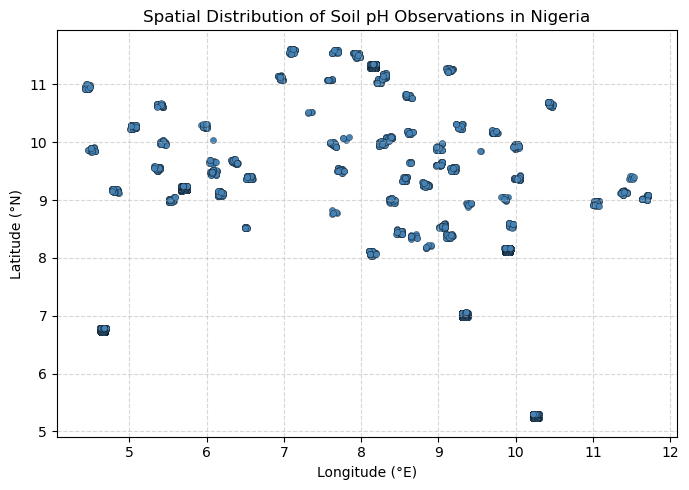

In [33]:
# Basic scatter plot: longitude vs latitude
plt.figure(figsize=(7, 5))
# s = marker size; edgecolor/linewidth = thin black outline so overlapping points stay visible
plt.scatter(df_clean['longitude'], df_clean['latitude'],
            s=20, color='steelblue', edgecolor='black', linewidth=0.2)
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.title('Spatial Distribution of Soil pH Observations in Nigeria')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
# dpi = 300 gives a print-quality image; bbox_inches='tight' trims extra white space
plt.savefig('figures/step5_spatial_basic.png', dpi=300, bbox_inches='tight')


plt.show()

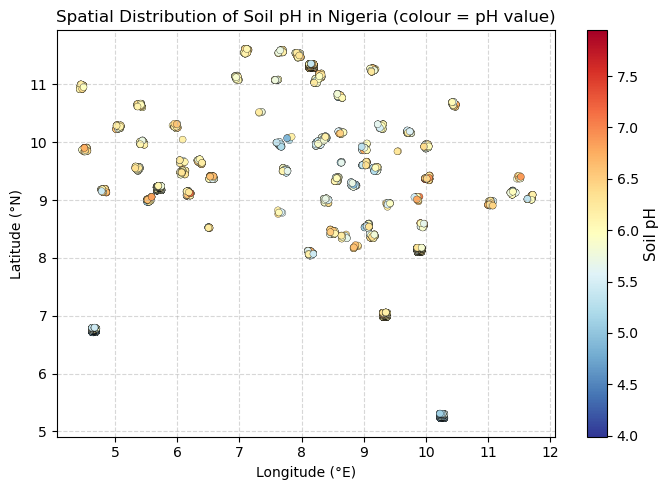

In [34]:
# Colour-coded scatter plot: pH value shown by colour
plt.figure(figsize=(7, 5))
# c = pH sets the colour of each point. Colormap 'RdYlBu_r': BLUE = low pH (more acidic), RED = high pH (more alkaline)
# NOTE: dense clusters overplot and the black outlines can darken them; smaller outlines or alpha < 1 would help
scatter = plt.scatter(df_clean['longitude'], df_clean['latitude'],
                      c=df_clean['ph'], cmap='RdYlBu_r',
                      s=25, edgecolor ='black', linewidth=0.2)
cbar = plt.colorbar(scatter)
cbar.set_label('Soil pH', fontsize=11)
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.title('Spatial Distribution of Soil pH in Nigeria (colour = pH value)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('figures/step5_spatial_ph_coloured.png', dpi=300, bbox_inches='tight')

plt.show()

In [35]:
# Round coordinates to the nearest whole degree and count records per 1-degree cell.
# Several nearby sampling sites can fall into one cell, so these counts are approximate cluster sizes.
# Count distinct spatial clusters to support interpretation
lon_rounded = df_clean['longitude'].round(0)
lat_rounded = df_clean['latitude'].round(0)

clusters = df_clean.groupby([lon_rounded, lat_rounded]).size().reset_index(name='count')
print(f"Approximate sampling clusters (rounded to nearest degree):")
print(clusters.sort_values('count', ascending=False).head(10).to_string(index=False))

Approximate sampling clusters (rounded to nearest degree):
 longitude  latitude  count
       8.0      11.0    461
       6.0       9.0    456
      10.0       8.0    349
       5.0       7.0    349
      10.0       5.0    342
       9.0       7.0    342
       9.0      10.0    213
       5.0      10.0    175
       8.0      10.0    174
       9.0       9.0    150


## Step 5 observations

- The scatter plot shows the geographic distribution of **4157** soil pH observations across Nigeria.
- Observations are **not uniformly distributed** across the country. Instead, they cluster at a small number of sampling locations, consistent with a survey-based sampling design rather than a national grid.
- The dominant clusters (largest counts in the cluster table, rounded to the nearest degree) are around **8°E, 11°N** (461 records), **6°E, 9°N** (456), **10°E, 8°N** (349), **5°E, 7°N** (349), **10°E, 5°N** (342) and **9°E, 7°N** (342). Smaller but still notable clusters occur around **9°E, 10°N**, **5°E, 10°N** and **8°E, 10°N**.
- Coverage is uneven. The plot shows no samples west of about 4.4°E, east of about 11.7°E, north of about 11.6°N or south of about 5.2°N, and the band between roughly 5.3°N and 6.7°N is almost empty.
- In the colour-coded plot (blue = lower pH, red = higher pH), **most clusters are pale yellow, i.e. pH of about 5.5–6.5**, which matches the mean of 5.918. The most clearly **acidic (blue)** clusters are in the south: around **10.3°E, 5.3°N** and **4.7°E, 6.8°N**. A few mid-latitude clusters, such as around 7.7°E, 10°N, also look light blue. **Higher-pH (orange) clusters** appear in parts of the 9–10°N band in the west (around 4.5–6°E) and in a few eastern sites (around 11.5°E, 9.4°N). No cluster is deep red, so strongly alkaline soils are rare.
- There is **no clear, simple north–south or east–west gradient**. pH seems to vary from one site to another, with neighbouring clusters often differing. Because points overlap heavily and the black outlines darken the dense clusters, the colours of those clusters are hard to judge, so these patterns are approximate.
- These visual patterns are consistent with the summary statistics in Step 4 and will be examined further in the distribution analysis in Step 6.

*Step 6: Distribution, Classification and Crop Suitability Analysis*
=

### *In this step, the frequency distribution of soil pH is examined using a histogram, and the median, quartiles, spread and potential outliers are summarised using a box plot. Potential outliers are identified using the interquartile range rule and retained in the analysis. Whether pH differs between the two depth categories (topsoil 0–20 cm and subsoil 20–50 cm) is examined and reported. Each observation is then classified into an agronomic pH category using established thresholds, and the suitability of sampled locations for six common Nigerian crops is assessed. Finally, pH is summarised by spatial cluster to identify regional differences.*

### 6a. Frequency distribution of soil pH

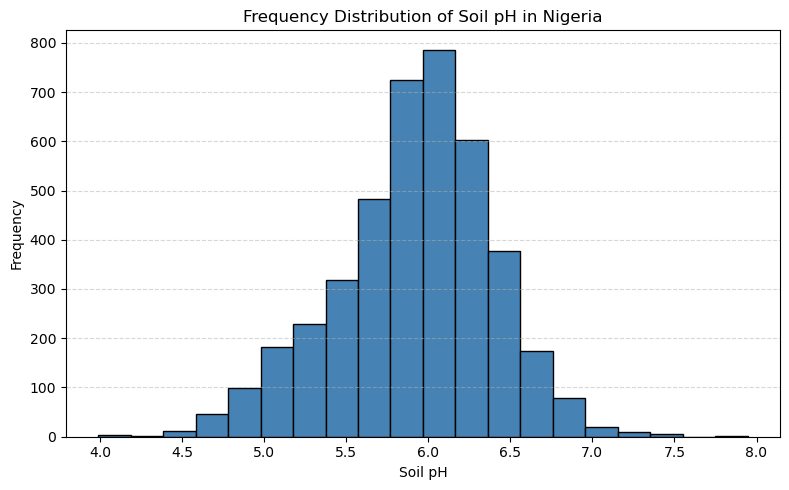

In [36]:
# bins = 20 splits the pH range (3.99-7.95) into 20 equal classes of about 0.2 pH units each
# Histogram of soil pH
plt.figure(figsize=(8, 5))
plt.hist(df_clean['ph'], bins=20, color='steelblue', edgecolor='black')
plt.xlabel('Soil pH')
plt.ylabel('Frequency')
plt.title('Frequency Distribution of Soil pH in Nigeria')
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures/step6_ph_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

### 6b. Box plot and outlier identification

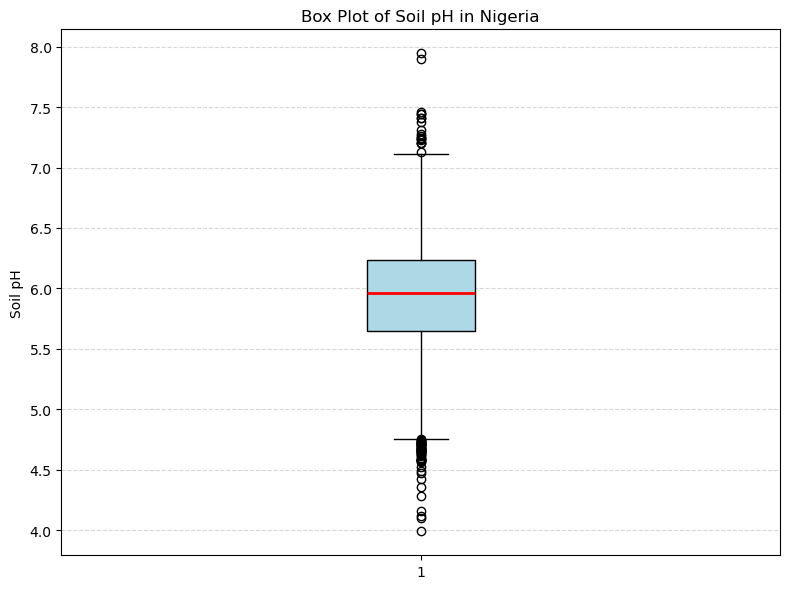

In [37]:
# Box = Q1 to Q3 (middle 50%), red line = median, whiskers reach the last value within 1.5 x IQR, circles = outliers.
# The x-axis label '1' is just Matplotlib's default for a single box.
# Box plot of soil pH
plt.figure(figsize=(8, 6))
plt.boxplot(df_clean['ph'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.ylabel('Soil pH')
plt.title('Box Plot of Soil pH in Nigeria')
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures/step6_ph_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [38]:
# Tukey's 1.5 x IQR rule: values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are flagged as potential outliers.
# They are only FLAGGED here, not removed, in line with the methodology.
# Identify potential outliers using the 1.5 x IQR rule
q1 = df_clean['ph'].quantile(0.25)
q3 = df_clean['ph'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = df_clean[(df_clean['ph'] < lower_fence) | (df_clean['ph'] > upper_fence)]

print("Q1              :", round(q1, 3))
print("Q3              :", round(q3, 3))
print("IQR             :", round(iqr, 3))
print("Lower fence     :", round(lower_fence, 3))
print("Upper fence     :", round(upper_fence, 3))
print("Number of outliers:", len(outliers))
print()
print("Outlier pH values:")
print(outliers['ph'].describe())

Q1              : 5.644
Q3              : 6.237
IQR             : 0.593
Lower fence     : 4.754
Upper fence     : 7.126
Number of outliers: 73

Outlier pH values:
count    73.000000
mean      5.316086
std       1.237443
min       3.990000
25%       4.601000
50%       4.687000
75%       7.129310
max       7.945400
Name: ph, dtype: float64


### 6c. Comparison of pH between depth categories

In [39]:
# Label format is 'upper-lower cm' (0-20 cm = topsoil, 20-50 cm = subsoil)
# Create a readable depth category label
depth_labels = df_clean.apply(
    lambda r: f"{int(r['horizon_upper'])}-{int(r['horizon_lower'])} cm", axis=1
)
df_clean['depth_category'] = depth_labels

print("Depth categories present:")
print(df_clean['depth_category'].value_counts())
print()
print("pH statistics by depth:")
print(df_clean.groupby('depth_category')['ph'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
).round(3))

Depth categories present:
depth_category
0-20 cm     3146
20-50 cm    1011
Name: count, dtype: int64

pH statistics by depth:
                count   mean  median    min    max    std
depth_category                                           
0-20 cm          3146  5.958   5.995  4.097  7.945  0.462
20-50 cm         1011  5.792   5.865  3.990  7.003  0.515


C:\Users\USER\AppData\Local\Temp\ipykernel_1488\256835508.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(depth_groups, labels=depth_names, patch_artist=True,


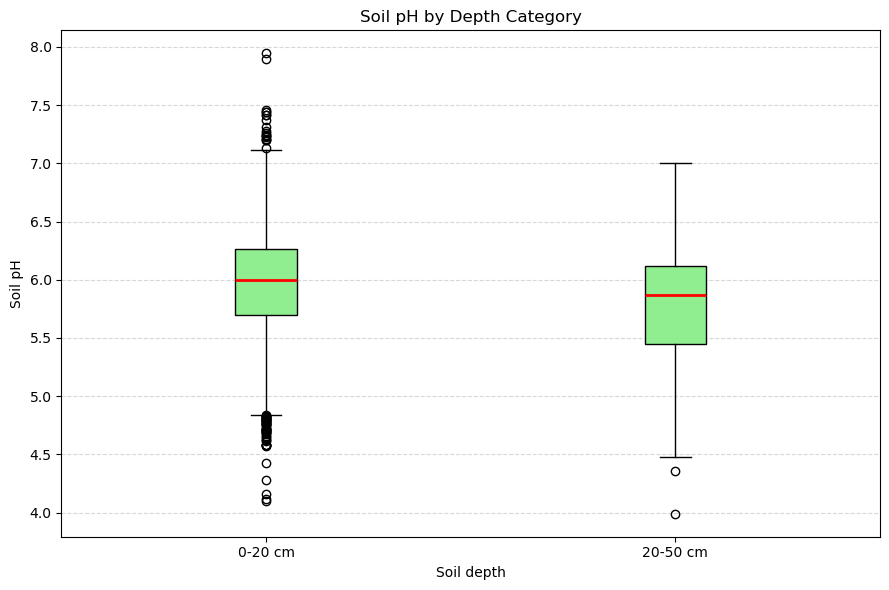

In [40]:
# NOTE: Matplotlib 3.9+ renamed 'labels' to 'tick_labels' (this causes the harmless deprecation warning).
# Keep 'labels' for Matplotlib < 3.9; switch to 'tick_labels' on newer versions.
# Box plots of pH by depth category
depth_groups = [g['ph'].values for _, g in df_clean.groupby('depth_category')]
depth_names = [n for n, _ in df_clean.groupby('depth_category')]

plt.figure(figsize=(9, 6))
plt.boxplot(depth_groups, labels=depth_names, patch_artist=True,
            boxprops=dict(facecolor='lightgreen', color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.ylabel('Soil pH')
plt.xlabel('Soil depth')
plt.title('Soil pH by Depth Category')
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures/step6_ph_by_depth.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
# Rule-of-thumb check (thresholds of 0.1 and 0.3 are informal, not a statistical test).
# A formal test (e.g. t-test or Mann-Whitney U) would be needed to claim statistical significance.
# Numeric check: is the difference in mean pH by depth meaningful?
depth_means = df_clean.groupby('depth_category')['ph'].mean().round(3)
print(f"Mean pH by depth:")
print(depth_means)
print()

if len(depth_means) == 2:
    diff = abs(depth_means.iloc[0] - depth_means.iloc[1])
    print(f"Absolute difference in mean pH between depths:", round(diff, 3))
    if diff < 0.1:
        print(f"-> Difference is negligible. Depth is not treated as a strong driver of pH here.")
    elif diff < 0.3:
        print(f"-> Small difference. Note it in interpretation but do not over-emphasise.")
    else:
        print(f"-> Noticeable difference. Report it in the interpretation as a depth-related pattern.")
else:
    print(f"-> Only one depth category present. Depth analysis not applicable.")

Mean pH by depth:
depth_category
0-20 cm     5.958
20-50 cm    5.792
Name: ph, dtype: float64

Absolute difference in mean pH between depths: 0.166
-> Small difference. Note it in interpretation but do not over-emphasise.


### 6d. Classification of soil pH into agronomic categories

In [42]:
# Thresholds: <4.5 strongly acidic | 4.5-5.5 acidic | 5.5-6.5 slightly acidic | 6.5-7.5 near neutral | >7.5 alkaline
# Lower bound of each class is inclusive, so a value of exactly 6.5 would fall in 'Near neutral'.
# Classify each pH value into an agronomic category
def classify_ph(value):
    if value < 4.5:
        return 'Strongly acidic'
    elif value < 5.5:
        return 'Acidic'
    elif value < 6.5:
        return 'Slightly acidic'
    elif value <= 7.5:
        return 'Near neutral'
    else:
        return 'Alkaline'

df_clean['ph_class'] = df_clean['ph'].apply(classify_ph)

print(f"Distribution of pH classes:")
print(df_clean['ph_class'].value_counts())
print()
print(f"Percentage by class:")
print((df_clean['ph_class'].value_counts(normalize=True) * 100).round(1))

Distribution of pH classes:
ph_class
Slightly acidic    3019
Acidic              744
Near neutral        383
Strongly acidic       9
Alkaline              2
Name: count, dtype: int64

Percentage by class:
ph_class
Slightly acidic    72.6
Acidic             17.9
Near neutral        9.2
Strongly acidic     0.2
Alkaline            0.0
Name: proportion, dtype: float64


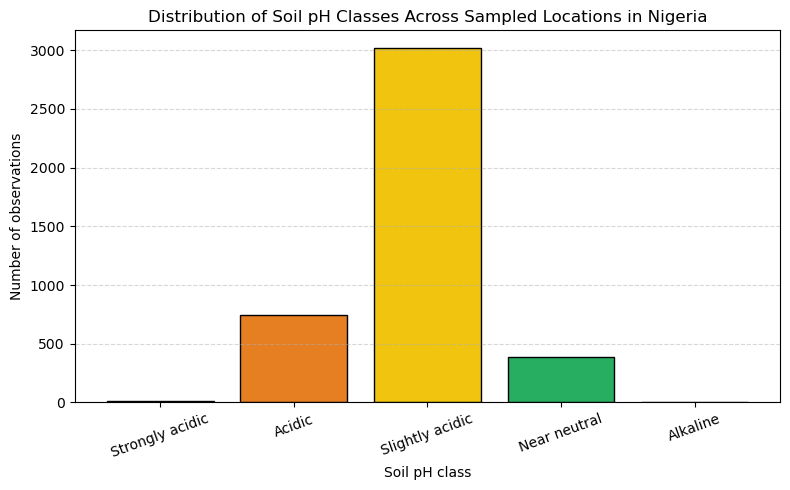

In [43]:
# reindex() puts the classes in order from most to least acidic (and skips any class with no records);
# bar colours run red -> blue to match acidic -> alkaline
# Visualise the proportion of samples in each pH class
class_counts = df_clean['ph_class'].value_counts()
order = ['Strongly acidic', 'Acidic', 'Slightly acidic', 'Near neutral', 'Alkaline']
class_counts = class_counts.reindex([c for c in order if c in class_counts.index])

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index, class_counts.values,
        color=['#c0392b', '#e67e22', '#f1c40f', '#27ae60', '#2980b9'],
        edgecolor='black')
plt.ylabel('Number of observations')
plt.xlabel('Soil pH class')
plt.title('Distribution of Soil pH Classes Across Sampled Locations in Nigeria')
plt.xticks(rotation=20)
plt.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig('figures/step6_ph_classes.png', dpi=300, bbox_inches='tight')
plt.show()

### 6e. Crop suitability assessment

In [44]:
# NOTE: the crop ranges below are hard-coded by the author. Cite the source (e.g. FAO or an agronomy reference) in the report.
# Both ends of each range are inclusive. Rice and cassava (and groundnut and cowpea) share identical ranges, so their results tie.
# Crop suitability ranges (common Nigerian crops)
crop_ranges = {
    'Maize':     (5.5, 7.0),
    'Rice':      (5.5, 6.5),
    'Cassava':   (5.5, 6.5),
    'Groundnut': (6.0, 7.0),
    'Tomato':    (6.0, 6.8),
    'Cowpea':    (6.0, 7.0),
}

# For each crop, compute the percentage of sampled locations with suitable pH
results = []
for crop, (low, high) in crop_ranges.items():
    suitable = ((df_clean['ph'] >= low) & (df_clean['ph'] <= high)).sum()
    total = df_clean['ph'].notna().sum()
    percent = round(100 * suitable / total, 1)
    results.append({
        'Crop': crop,
        'Suitable pH range': f'{low} - {high}',
        'Suitable locations': suitable,
        'Total locations': total,
        'Percent suitable (%)': percent
    })

crop_df = pd.DataFrame(results).sort_values('Percent suitable (%)', ascending=False)
print(crop_df.to_string(index=False))

crop_df.to_csv('figures/step6_crop_suitability.csv', index=False)

     Crop Suitable pH range  Suitable locations  Total locations  Percent suitable (%)
    Maize         5.5 - 7.0                3372             4157                  81.1
     Rice         5.5 - 6.5                3019             4157                  72.6
  Cassava         5.5 - 6.5                3019             4157                  72.6
Groundnut         6.0 - 7.0                1896             4157                  45.6
   Cowpea         6.0 - 7.0                1896             4157                  45.6
   Tomato         6.0 - 6.8                1831             4157                  44.0


*Crop pH suitability ranges are standard published agronomic values for these crops. If the department prefers alternative reference ranges, the classification can be re-run with those values without changing the method.*

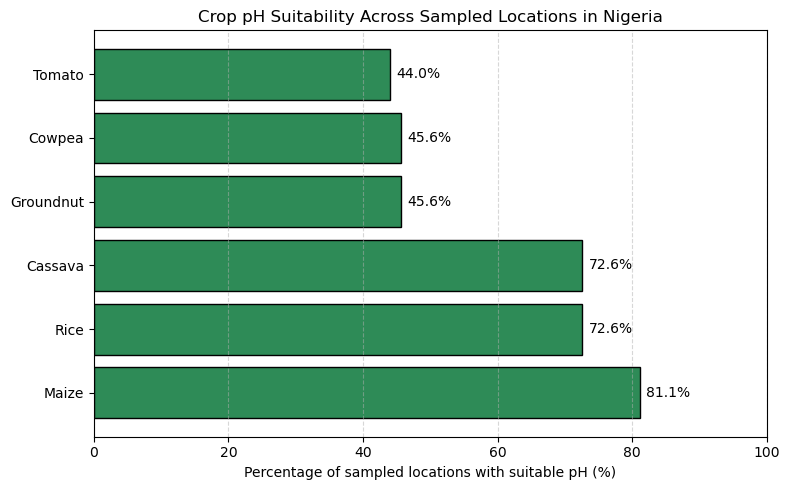

In [45]:
# Horizontal bar chart of the crop suitability table; the loop writes the percentage label at the end of each bar
# Visualise crop suitability
plt.figure(figsize=(8, 5))
plt.barh(crop_df['Crop'], crop_df['Percent suitable (%)'],
         color='seagreen', edgecolor='black')
plt.xlabel('Percentage of sampled locations with suitable pH (%)')
plt.title('Crop pH Suitability Across Sampled Locations in Nigeria')
plt.xlim(0, 100)
for i, v in enumerate(crop_df['Percent suitable (%)']):
    plt.text(v + 1, i, f'{v}%', va='center')
plt.grid(True, linestyle='--', alpha=0.5, axis='x')
plt.tight_layout()
plt.savefig('figures/step6_crop_suitability.png', dpi=300, bbox_inches='tight')
plt.show()

### 6f. Regional pH summary

In [46]:
# Round coordinates to the nearest whole degree to group nearby sampling sites into 1-degree cells.
# One cell can hold several sites, so these are approximate regional groups, not administrative regions.
# Summarise pH by spatial cluster (rounded coordinates)
df_clean['lon_cluster'] = df_clean['longitude'].round(0)
df_clean['lat_cluster'] = df_clean['latitude'].round(0)

regional = df_clean.groupby(['lon_cluster', 'lat_cluster'])['ph'].agg(
    ['count', 'mean', 'median']
).round(2).reset_index()

regional = regional[regional['count'] >= 5]  # only clusters with enough data
print("Regional pH summary (clusters with >=5 observations):")
print(regional.sort_values('mean').to_string(index=False))

regional.to_csv('figures/step6_regional_ph.csv', index=False)

Regional pH summary (clusters with >=5 observations):
 lon_cluster  lat_cluster  count  mean  median
        10.0          5.0    342  5.30    5.27
         5.0          7.0    349  5.32    5.28
         9.0          9.0    150  5.71    5.68
         8.0         10.0    174  5.75    5.77
         9.0         10.0    213  5.87    5.84
         7.0         11.0     49  5.87    5.83
         9.0         11.0     82  5.91    5.91
         6.0          9.0    456  5.95    5.96
         8.0          8.0     67  5.96    5.98
        10.0          8.0    349  5.97    5.99
         8.0         12.0     54  5.98    5.96
         8.0          9.0     55  5.98    5.92
         4.0         10.0      7  6.08    5.93
         5.0         10.0    175  6.09    6.07
        10.0         10.0     96  6.09    6.08
         5.0         11.0     47  6.10    6.06
        10.0         11.0     45  6.10    6.05
        11.0          9.0     87  6.12    6.14
         7.0         12.0     50  6.12    6.05
      

## Step 6 observations

### Distribution
- Soil pH values ranged from **3.990** to **7.945** with a mean of **5.918** and a median of **5.963**.
- The distribution was **single-peaked and bell-shaped, slightly skewed toward low pH** (skewness -0.336), with the bulk of values between **5.644** and **6.237**. The tallest histogram bars lie at about 5.8–6.2, and the left (acidic) tail is slightly longer than the right.

### Outliers
- Using the 1.5 × IQR rule, **73** potential outliers (about 1.8% of observations) were identified outside the range **4.754** to **7.126**.
- Most are on the acidic side: the lower quartile and median of the outlier values are about 4.6 and 4.7, whereas the rest lie above the upper fence, at about 7.13–7.95.
- These outliers were **retained** in the analysis as the methodology specifies.

### Depth comparison
- Two depth categories were present: **topsoil (0–20 cm, 3146 records)** and **subsoil (20–50 cm, 1011 records)**.
- Mean pH was **5.958** in topsoil and **5.792** in subsoil, a difference of **0.166** pH units (medians 5.995 vs 5.865).
- The difference is **small**: subsoil is slightly more acidic, but the two distributions overlap substantially, so depth is not treated as a strong driver of pH. Topsoil shows more outliers, but it also has about three times as many records.

### pH classification
- **72.6%** of sampled locations were slightly acidic (5.5–6.5), the most common class.
- **17.9%** were acidic (4.5–5.5), and **0.2%** (9 records) were strongly acidic (below 4.5).
- **9.2%** were near neutral (6.5–7.5), and **under 0.1%** (2 records) were alkaline (above 7.5).
- The dominant class was **slightly acidic**. About **91%** of locations fall below pH 6.5, so most soils are on the acidic side of neutral, but only about 18% are acidic enough (below 5.5) to be of real concern.

### Crop suitability
- **Maize** (81.1%) showed the highest suitability, followed by **rice and cassava** (both 72.6%, because they share the same range), with over **72%** of sampled locations within their preferred pH range.
- **Tomato** showed the lowest suitability, with only **44.0%** of sampled locations suitable (groundnut and cowpea were similar, at 45.6%).
- These results indicate that **maize, rice and cassava are broadly compatible with the sampled soils, while groundnut, cowpea and tomato fall within their preferred range at fewer than half of locations**. Roughly 54% of locations have pH below 6.0 (derived from the counts above), so these crops would need liming or careful site selection at many locations.

### Regional variation
- The regional summary (28 one-degree clusters with at least 5 observations) showed that mean pH varied from **5.30** in the cluster around 10°E, 5°N (342 records) to **6.32** in the cluster around 10°E, 9°N (107 records), a spread of about **1.0** pH unit between cluster means.
- Only two clusters stand out as clearly more acidic: 10°E, 5°N (5.30) and 5°E, 7°N (5.32, 349 records). Together they hold 691 records (about 17% of the data) and probably account for much of the acidic class. The other 26 clusters have mean pH of about 5.7–6.3, and 22 of them are between 5.9 and 6.3.
- This regional variation means that **a single national recommendation would be misleading**; crop choice and liming decisions should be based on local soil testing.

*Step 7: Interpretation, Recommendations and Reporting*
=

### *In this step, the results from Steps 4–6 are interpreted to identify broad patterns and variations in soil pH. The findings are translated into practical, directional recommendations for agricultural decision-making, and the study's limitations and conclusion are stated.*

### 7a. Consolidated summary of key metrics

In [47]:
# Gather the headline numbers from Steps 3-6 into one dictionary so the write-up uses verified values,
# then save it as a CSV for the report appendix. Needs df_nigeria, df_clean, outliers, crop_df from earlier cells.
# Pull every headline number into one summary so the write-up is grounded in verified values
ph = df_clean['ph']

report = {
    'Total observations (filtered)': len(df_nigeria),
    'Observations with pH': int(ph.count()),
    'Mean pH': round(ph.mean(), 3),
    'Median pH': round(ph.median(), 3),
    'Min pH': round(ph.min(), 3),
    'Max pH': round(ph.max(), 3),
    'Std dev pH': round(ph.std(), 3),
    'Q1': round(ph.quantile(0.25), 3),
    'Q3': round(ph.quantile(0.75), 3),
    'IQR': round(ph.quantile(0.75) - ph.quantile(0.25), 3),
    'Outliers (1.5 x IQR)': len(outliers),
    'Dominant pH class': df_clean['ph_class'].mode().iloc[0],
    'Top suitable crop': crop_df.iloc[0]['Crop'],
    'Top crop suitability (%)': crop_df.iloc[0]['Percent suitable (%)'],
    'Lowest suitable crop': crop_df.iloc[-1]['Crop'],
    'Lowest crop suitability (%)': crop_df.iloc[-1]['Percent suitable (%)'],
}

print("=== FINAL SUMMARY FOR REPORT ===")
for k, v in report.items():
    print(f"{k:32s}: {v}")

pd.DataFrame(list(report.items()), columns=['Metric', 'Value']).to_csv(
    'figures/step7_final_summary.csv', index=False
)
print()
print("Saved to figures/step7_final_summary.csv")

=== FINAL SUMMARY FOR REPORT ===
Total observations (filtered)   : 4157
Observations with pH            : 4157
Mean pH                         : 5.918
Median pH                       : 5.963
Min pH                          : 3.99
Max pH                          : 7.945
Std dev pH                      : 0.48
Q1                              : 5.644
Q3                              : 6.237
IQR                             : 0.593
Outliers (1.5 x IQR)            : 73
Dominant pH class               : Slightly acidic
Top suitable crop               : Maize
Top crop suitability (%)        : 81.1
Lowest suitable crop            : Tomato
Lowest crop suitability (%)     : 44.0

Saved to figures/step7_final_summary.csv


## Interpretation

### Overview
The analysis examined soil pH across **4157** observations in Nigeria, drawn from two source types (`afsis_spectral` and `afsis_wetchem`) and two depth categories (topsoil 0–20 cm and subsoil 20–50 cm).

### Central tendency and variability
The mean soil pH was **5.918** and the median was **5.963**, indicating that the typical soil in the study area is **slightly acidic**: below neutral (pH 7) but above the strongly acidic range. Values ranged from **3.990** to **7.945**, a spread of **3.955** pH units. The standard deviation of **0.480** indicates **low-to-moderate** variability across the study area, and the middle 50% of observations lie within a narrow band (5.644 to 6.237).

### Spatial pattern
The scatter plot in Step 5 showed that observations are **not uniformly distributed** across Nigeria but cluster at a small number of sampling locations. In the colour-coded plot, **most clusters were pale yellow (pH of about 5.5–6.5), while the clearest acidic clusters were in the south (around 10.3°E, 5.3°N and 4.7°E, 6.8°N)**. The regional summary in Step 6 confirms this: these two areas have the lowest mean pH (5.30 and 5.32), and there is no simple north–south or east–west gradient. This pattern suggests that soil pH varies meaningfully between sampled regions, which could reflect differences in parent material, rainfall and land use; however, this analysis did not test the causes. Large parts of the country, including the far north and the southern edge, were not sampled.

### Distribution and outliers
The histogram showed a distribution that is **single-peaked and slightly skewed toward low pH**, with the bulk of values between **5.644** and **6.237**. The box plot identified **73** potential outliers (about 1.8%), most of them on the acidic side, which were retained because unusual but potentially valid pH measurements should not be removed without justification.

### Depth comparison
Mean pH was **5.958** in topsoil and **5.792** in subsoil, a difference of **0.166** pH units. This difference is small, so depth is not treated as a strong driver of pH here; subsoil is only slightly more acidic.

### pH classification
The classification showed that **72.6%** of sampled locations fell into the slightly acidic class (pH 5.5–6.5) — the most common category. **17.9%** were acidic (4.5–5.5), and **0.2%** were strongly acidic (below 4.5). Only **9.2%** were near neutral, and under **0.1%** were alkaline. This distribution indicates that most sampled soils are on the acidic side of neutral, which is significant for nutrient availability.

### Crop suitability
Applying published pH suitability ranges to the sampled locations, **maize** (81.1%) and **rice and cassava** (72.6% each) showed the highest suitability, with over **72%** of sampled locations within their preferred range. **Tomato** showed the lowest suitability, with only **44.0%** of sampled locations suitable (groundnut and cowpea: 45.6%). This means that **maize, rice and cassava are broadly compatible with the sampled soils, while groundnut, cowpea and tomato would require liming or careful site selection at many locations**.

### Regional variation
Regional summary showed that mean pH varied from **5.30** in one cluster (around 10°E, 5°N) to **6.32** in another (around 10°E, 9°N). This regional variation means that **a single national recommendation would be misleading**; crop choice and liming decisions should be based on local soil testing.

### Relevance to agricultural soil assessment
Soil pH is a key indicator of nutrient availability. In acidic soils (pH below about 5.5), phosphorus becomes less available, aluminium can reach toxic levels, and liming may be required. In soils with a pH of about 6.0–7.0, most major nutrients are readily available. The findings suggest that **soils in the sampled areas are predominantly slightly acidic, with about 18% acidic or strongly acidic, which has direct implications for crop selection and the need for liming in some locations**. These findings are preliminary and descriptive — they identify broad patterns that warrant further investigation, rather than providing field-level prescriptions.

## Practical recommendations

Based on the findings, the following recommendations can be made:

1. **For soils classified as acidic or strongly acidic** (pH below 5.5), **liming is recommended before planting** pH-sensitive crops such as maize, groundnut and tomato. Agricultural lime (calcium carbonate) raises pH and reduces aluminium toxicity, improving phosphorus availability.

2. **For soils classified as slightly acidic** (pH 5.5–6.5), most common Nigerian crops — including **cassava, rice and maize** — can be cultivated without liming. These soils represent the most versatile category in the dataset.

3. **For soils classified as near neutral** (pH 6.5–7.5), crops such as **groundnut, tomato and cowpea** can generally be grown, since their preferred ranges extend to about pH 6.8–7.0. Soils above about pH 7.0 fall slightly outside those ranges, so check local conditions. Nutrient availability is generally good in this range.

4. **Regional variation matters.** Because pH varied between sampling clusters, **crop selection and liming decisions should be based on local soil testing rather than national averages**. A single recommendation for "Nigeria" would be misleading.

5. **Regular soil testing is the first step.** These findings describe patterns at sampled locations, not at every farm. Farmers should test their own soil pH before applying amendments.

## What this analysis can and cannot decide

**What it can support:**
- Identifying which crops are broadly compatible with the sampled soils
- Flagging regions where liming may be needed before planting
- Prioritising crops based on pH suitability at sampled locations

**What it cannot decide:**
- It cannot prescribe a specific lime quantity — that requires soil texture, organic matter and target pH per crop, none of which are in this dataset.
- It cannot guarantee yield — pH is one of many factors including rainfall, nutrients, pests and management.
- It cannot represent every farm — the samples cluster at specific locations.

This is why the recommendations are **directional, not prescriptive**: they guide crop choice and flag where further testing is warranted, rather than specifying exact treatments.

## Limitations

1. **pH alone is insufficient.** Soil pH does not capture nutrient content, organic matter, texture, or salinity. A full agricultural assessment requires additional soil properties.
2. **Uneven spatial sampling.** Observations cluster at a small number of locations rather than covering Nigeria uniformly, so the findings describe sampled sites, not the country as a whole.
3. **Two source types.** The dataset combines `afsis_spectral` and `afsis_wetchem` records. Any systematic difference between methods would affect the combined statistics.
4. **No crop or yield data.** The analysis cannot link pH to agricultural productivity; it describes soil condition and crop pH compatibility only.
5. **Descriptive scope.** The project describes pH patterns and applies agronomic thresholds but does not model them spatially or test causal hypotheses.

## Conclusion

This project analysed the distribution and variability of soil pH in Nigeria using Python. Descriptive statistics, spatial visualisation, distribution analysis and classification showed that soil pH is **slightly acidic overall, with a median of 5.963, low-to-moderate variability, a dominant slightly acidic class (72.6% of locations), a small difference between topsoil and subsoil, and clear regional variation between sampling clusters, with the most acidic sites in the south**. Applying published crop suitability ranges indicated that **maize (81.1%), rice and cassava (72.6% each) are broadly compatible with the sampled soils, while groundnut, cowpea and tomato (44–46%) would require liming or careful site selection at many locations**. These findings provide preliminary information relevant to agricultural soil assessment and translate raw measurements into decision-relevant guidance, while clearly stating the limitations of pH data alone. Further work should extend the analysis to other soil properties and link pH patterns to crop yield data.